In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler

Etapa 1 (Entendimento): Identificamos que o problema é de classificação. É crucial separar corretamente o que são as features (variáveis explicativas) e o label (o que queremos prever). O arquivo Base4.csv contém três colunas: duas colunas de coordenadas (que funcionam como features ou variáveis de entrada) e uma terceira coluna (2) que funciona como o label (o rótulo ou a classe que o modelo deve prever).

Etapa 2 (EDA): Utilizamos histogramas para entender a distribuição e a matriz de correlação para verificar se existe redundância nos dados. Isso ajuda a evitar que variáveis irrelevantes confundam a rede neural.

Colunas do dataset: Index([0, 1, 2], dtype='int64')
Primeiras linhas:
            0          1  2
0 -19.273006 -18.236898  1
1 -20.106840 -20.714055  1
2 -21.396553 -22.397874  1
3 -19.971450 -19.914267  1
4 -23.340873 -21.380371  1


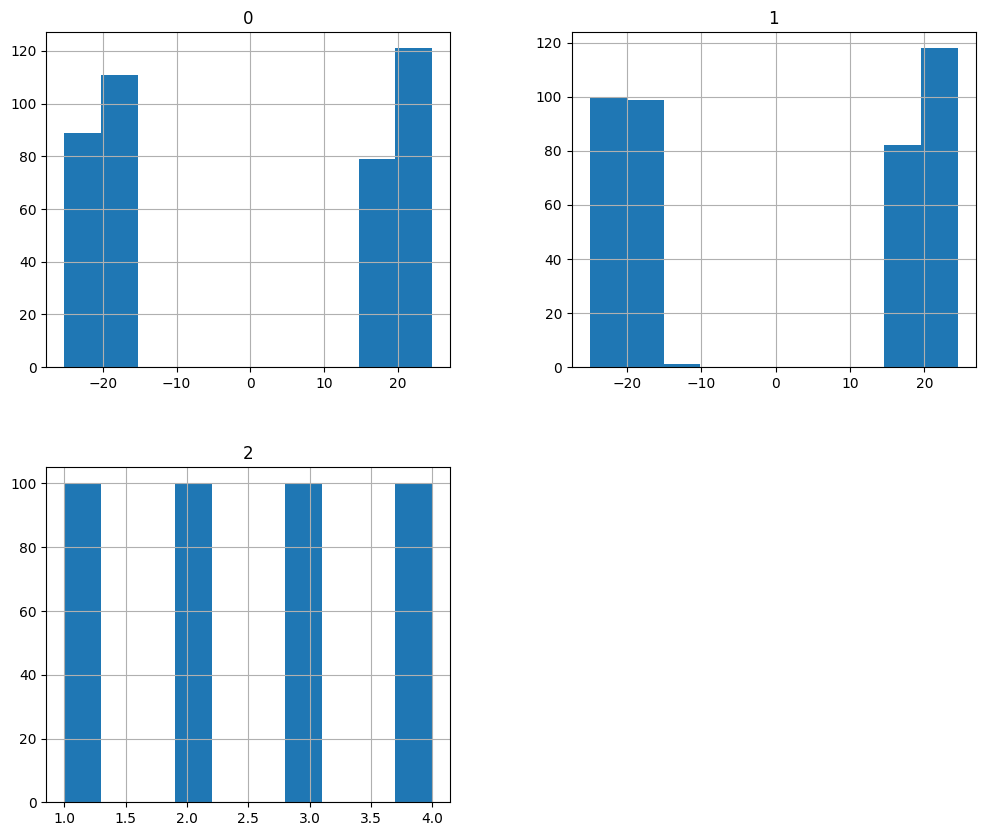

/tmp/ipykernel_17842/1725447610.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=2, y=0, ax=axes[0], palette='Set2')
/tmp/ipykernel_17842/1725447610.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=2, y=1, ax=axes[1], palette='Set2')


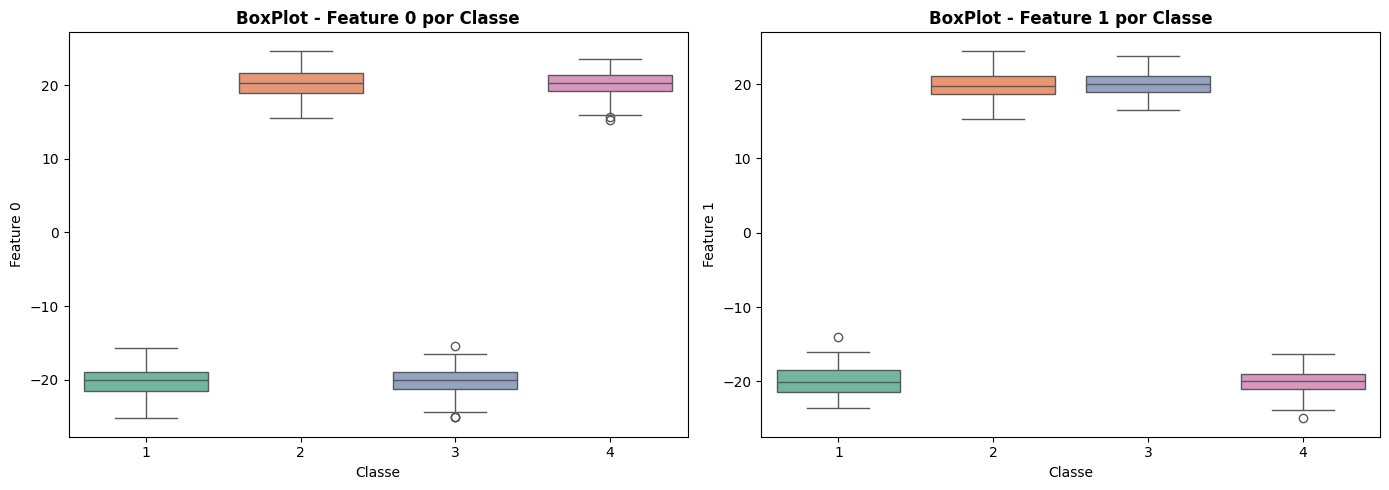

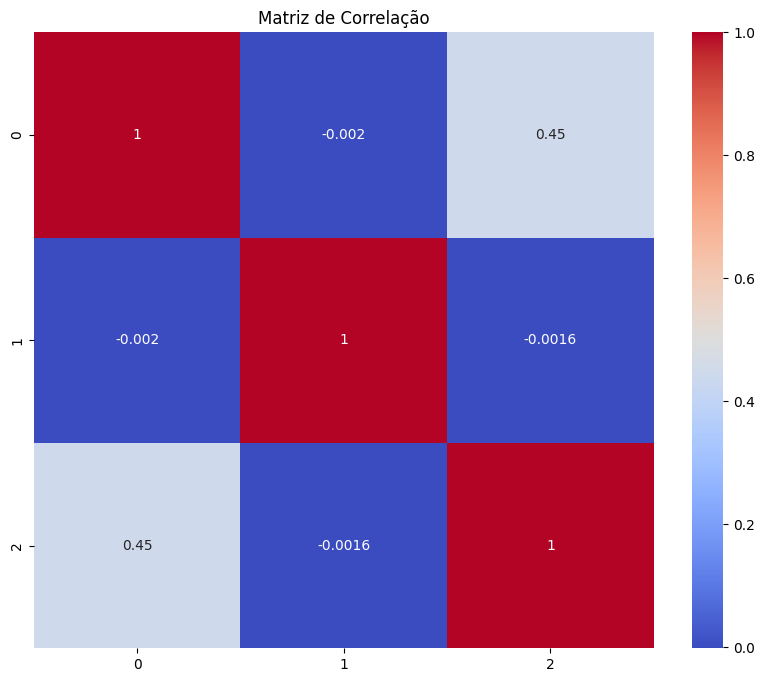

In [17]:
def carregar_csv(caminho):
    df = pd.read_csv(caminho, header=None, names=[0, 1, 2])

    df[0] = df[0].astype(str).str.replace('"', '').str.replace(',', '.').astype(float)
    df[1] = df[1].astype(str).str.replace('"', '').str.replace(',', '.').astype(float)
    df[2] = df[2].astype(int)

    dados = df[[0, 1]].values
    rotulos = df[2].values - 1

    return df, dados, rotulos

df, dados, rotulos = carregar_csv('Base4.csv')

# Etapa 1: Entendimento
print("Colunas do dataset:", df.columns)
print("Primeiras linhas:\n", df.head())


# Etapa 2: Análise Exploratória (EDA)
df.hist(figsize=(12, 10))
plt.show()

# BoxPlot por classe
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, x=2, y=0, ax=axes[0], palette='Set2')
axes[0].set_title('BoxPlot - Feature 0 por Classe', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Classe')
axes[0].set_ylabel('Feature 0')

sns.boxplot(data=df, x=2, y=1, ax=axes[1], palette='Set2')
axes[1].set_title('BoxPlot - Feature 1 por Classe', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Classe')
axes[1].set_ylabel('Feature 1')
plt.tight_layout()
plt.show()

# Colorindo os pontos pela classe (coluna 2)
# sns.pairplot(df, hue=2, palette='viridis', diag_kind='kde')
# plt.show()

# Matriz de correlação
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title("Matriz de Correlação")
plt.show()

Etapa 4 (Escalonamento): Como as ANNs realizam cálculos matemáticos baseados nos pesos dos neurônios, atributos com escalas diferentes podem causar instabilidade no treinamento. O StandardScaler garante que todos os atributos estejam na mesma "escala de importância".

In [ ]:
# Etapa 4: Escalonamento dos dados
X = df[[0, 1]] #features
y = df[2] #target

# Aplicando a normalização
scaler = MinMaxScaler() #melhor para quando há pouco outlier
X_scaled = scaler.fit_transform(X)

# Transformando de volta em DataFrame para facilitar a visualização
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)
print("Dados escalonados (primeiras 5 linhas):\n", X_scaled_df.head())

Dados escalonados (primeiras 5 linhas):
           0         1
0  0.119202  0.136188
1  0.102484  0.086120
2  0.076624  0.052086
3  0.105198  0.102285
4  0.037640  0.072652


Etapa 5 (Implementação da Separação): Como precisamos dividir em três partes, fazemos o processo em dois passos: primeiro separamos o treino e o resto, e depois dividimos o "resto" em validação e teste.
- Treino (70%): É usado pelo algoritmo para aprender os pesos das conexões neurais durante o forward propagation e backpropagation.  
- Validação (15%): Essencial para monitorar o treinamento e ajustar hiperparâmetros (como número de épocas, taxa de aprendizado ou número de neurônios) sem enviesar o modelo. Ajuda a detectar o overfitting precocemente.  
- Teste (15%): Atua como o "juiz final". O modelo nunca "vê" esses dados durante o treinamento ou ajuste, fornecendo uma métrica imparcial do quão bem ele generaliza para novos dados.  

In [19]:
from sklearn.model_selection import train_test_split

# Separar em Treino (70%) e Resto (30%)
X_train, X_rest, y_train, y_rest = train_test_split(
    X_scaled, y, test_size=0.30, random_state=42
)

# Separar o Resto em Validação (15%) e Teste (15%)
# Como o Resto era 30% do total, dividimos ele ao meio (0.5 de 0.3 = 0.15)
X_val, X_test, y_val, y_test = train_test_split(
    X_rest, y_rest, test_size=0.50, random_state=42
)

print(f"Tamanho do treino: {len(X_train)} amostras")
print(f"Tamanho da validação: {len(X_val)} amostras")
print(f"Tamanho do teste: {len(X_test)} amostras")

Tamanho do treino: 280 amostras
Tamanho da validação: 60 amostras
Tamanho do teste: 60 amostras


Etapa 6 (Construção da MLP): Utilizamos o Keras Sequential para construir uma rede neural artificial com múltiplas camadas. A primeira camada possui 8 neurônios (camada oculta), uma segunda camada com 10 neurônios para reduzir a complexidade, e uma camada de saída com 4 neurônios (uma para cada classe) com função de ativação softmax. A ativação ReLU nas camadas ocultas introduz não-linearidade, permitindo que a rede aprenda padrões complexos.

In [25]:
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense
from keras.optimizers import Adam
from keras import regularizers
from keras.callbacks import EarlyStopping

# Etapa 6: Construção da MLP usando Keras Sequential
# Ajustando os rótulos para começar do 0
y_train_adjusted = y_train - 1
y_val_adjusted = y_val - 1

# Determinando o número de classes
num_classes = 4
print(f"Número de classes: {num_classes}")

# Construindo a arquitetura da rede neural
model = Sequential([
    # Primeira camada oculta: 8 neurônios com ativação ReLU
    Dense(8, activation='relu', input_shape=(2,), name='camada_oculta_1'),
    
    # Segunda camada oculta: 10 neurônios com ativação ReLU
    Dense(10, activation='relu', name='camada_oculta_2'),
    
    # Camada de saída: 4 neurônios (uma por classe) com ativação softmax
    Dense(4, activation='softmax', name='camada_saida')
])

print("Arquitetura da Rede Neural: ")
model.summary() #exibe o conteudo

model.compile(
    optimizer=Adam(learning_rate=0.001), #ajusta a taxa de aprendizado automaticamente
    loss='sparse_categorical_crossentropy', #para classificação multiclasse com labels inteiros
    metrics=['accuracy'] #métrica de desempenho
)

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

print("TREINAMENTO:")
history = model.fit(
    X_train, y_train_adjusted,
    epochs=100,
    batch_size=16,
    validation_data=(X_val, y_val_adjusted),
    callbacks=[early_stopping],
    verbose=1
)

print("Treinamento Concluído")
print(f"Acurácia de treino final: {history.history['accuracy'][-1]:.4f}")
print(f"Acurácia de validação final: {history.history['val_accuracy'][-1]:.4f}")


Número de classes: 4
Arquitetura da Rede Neural: 


/home/debora/Documents/IA/machine-learning/.venv/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ camada_oculta_1 (Dense)         │ (None, 8)              │            24 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ camada_oculta_2 (Dense)         │ (None, 10)             │            90 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ camada_saida (Dense)            │ (None, 4)              │            44 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 158 (632.00 B)

 Trainable params: 158 (632.00 B)

 Non-trainable params: 0 (0.00 B)

TREINAMENTO:
Epoch 1/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - accuracy: 0.2500 - loss: 1.3994 - val_accuracy: 0.3000 - val_loss: 1.3565
Epoch 2/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.2500 - loss: 1.3804 - val_accuracy: 0.3000 - val_loss: 1.3442
Epoch 3/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.3036 - loss: 1.3641 - val_accuracy: 0.4667 - val_loss: 1.3317
Epoch 4/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.4750 - loss: 1.3477 - val_accuracy: 0.5000 - val_loss: 1.3170
Epoch 5/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.4929 - loss: 1.3293 - val_accuracy: 0.4667 - val_loss: 1.3003
Epoch 6/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.3893 - loss: 1.3093 - val_accuracy: 0.3000 - val_loss: 1.2811
Epoch 7/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.2500 - loss: 1.2869 - val_accuracy: 0.3000 - val_loss: 1.2565
Epoch 8/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.2821 - loss: 1.2581 - val

Etapa 7 (Análise do Treinamento com Forward e Backpropagation): Na Etapa 6, durante cada época, o modelo executou:
- **Forward Propagation**: Os dados de treino passam pelas camadas (entrada → oculta 1 → oculta 2 → saída) gerando predições
- **Backpropagation**: O erro é calculado e propagado de trás para frente, atualizando os pesos de cada neurônio
- **Otimização**: O optimizer Adam ajusta os pesos para minimizar o erro

Agora visualizamos esse processo através do histórico de treinamento, mostrando como a acurácia e o erro evoluíram ao longo das 100 épocas.

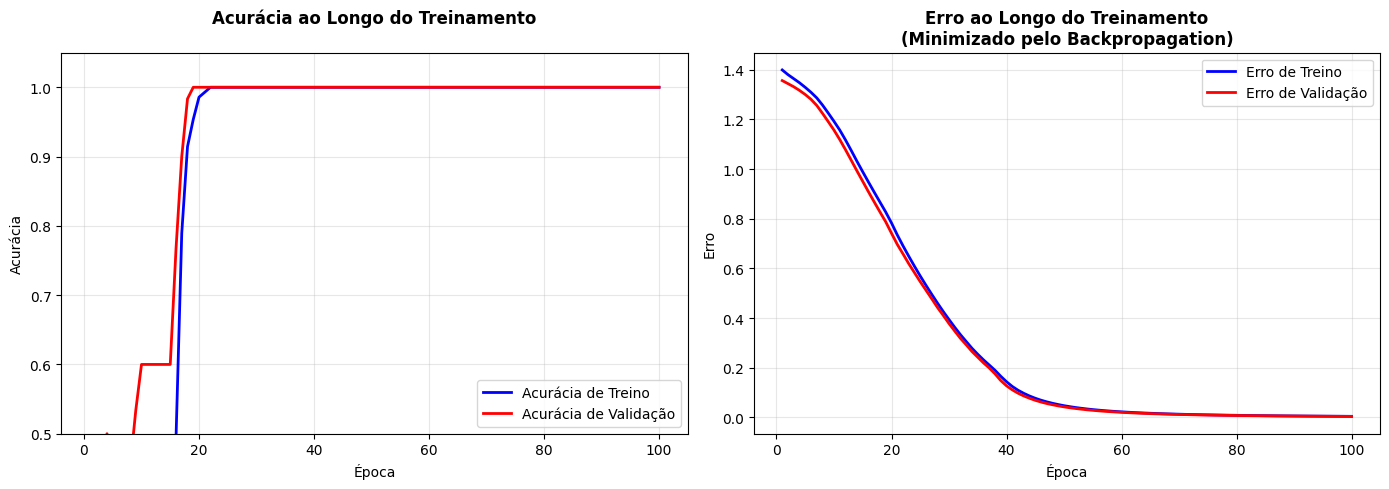


RESUMO DO TREINAMENTO:
Total de épocas: 100
Acurácia inicial (época 1): 0.2500
Acurácia final (época 100): 1.0000
Loss inicial (época 1): 1.399368
Loss final (época 100): 0.004208

DESEMPENHO NA VALIDAÇÃO:
Acurácia final validação: 1.0000
Loss final validação: 0.003950
Melhor desempenho na época 100 (loss: 0.003950)

DINÂMICA DO BACKPROPAGATION:
Redução total do loss: 1.395160
Redução média por época: 0.013952
Épocas até 90% da acurácia final: 17


In [28]:
# Análise do Treinamento (Forward Propagation e Backpropagation)
import numpy as np

# Extraindo dados do histórico de treinamento
epochs = range(1, len(history.history['accuracy']) + 1)
train_accuracy = history.history['accuracy']
val_accuracy = history.history['val_accuracy']
train_loss = history.history['loss']
val_loss = history.history['val_loss']

# Acurácia (Forward + Backpropagation)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico de Acurácia
axes[0].plot(epochs, train_accuracy, 'b-', label='Acurácia de Treino', linewidth=2)
axes[0].plot(epochs, val_accuracy, 'r-', label='Acurácia de Validação', linewidth=2)
axes[0].set_title('Acurácia ao Longo do Treinamento\n', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('Acurácia')
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[0].set_ylim([0.5, 1.05])

# Gráfico de Erro
axes[1].plot(epochs, train_loss, 'b-', label='Erro de Treino', linewidth=2)
axes[1].plot(epochs, val_loss, 'r-', label='Erro de Validação', linewidth=2)
axes[1].set_title('Erro ao Longo do Treinamento\n(Minimizado pelo Backpropagation)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Época')
axes[1].set_ylabel('Erro')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Análise detalhada do treinamento Forward Propagation e Backpropagation
print(f"\nRESUMO DO TREINAMENTO:")
print(f"Total de épocas: {len(epochs)}")
print(f"Acurácia inicial (época 1): {train_accuracy[0]:.4f}")
print(f"Acurácia final (época {len(epochs)}): {train_accuracy[-1]:.4f}")
print(f"Loss inicial (época 1): {train_loss[0]:.6f}")
print(f"Loss final (época {len(epochs)}): {train_loss[-1]:.6f}")

print(f"\nDESEMPENHO NA VALIDAÇÃO:")
print(f"Acurácia final validação: {val_accuracy[-1]:.4f}")
print(f"Loss final validação: {val_loss[-1]:.6f}")

# Encontrar época de melhor validação
best_val_epoch = np.argmin(val_loss) + 1
best_val_loss = val_loss[best_val_epoch - 1]
print(f"Melhor desempenho na época {best_val_epoch} (loss: {best_val_loss:.6f})")

print(f"\nDINÂMICA DO BACKPROPAGATION:")
# Redução média do loss por época
loss_reduction = train_loss[0] - train_loss[-1]
print(f"Redução total do loss: {loss_reduction:.6f}")
print(f"Redução média por época: {loss_reduction/len(epochs):.6f}")

# Velocidade de convergência (épocas até 90% da melhoria final)
target_accuracy = 0.9 * train_accuracy[-1]
convergence_epoch = next((i for i, acc in enumerate(train_accuracy) if acc >= target_accuracy), len(epochs))
print(f"Épocas até 90% da acurácia final: {convergence_epoch}")


Etapa 8 (Validação - Overfitting, Underfitting e Convergência):
- **Overfitting**: Quando o modelo aprende TOO BEM os dados de treino, memorizando detalhes específicos. Ocorre quando gap entre acurácia de treino e validação aumenta significativamente.
- **Underfitting**: Quando o modelo não aprende suficientemente nem no treino. Acurácia baixa em ambos (treino e validação).
- **Convergência**: Quando o modelo estabiliza e o loss/acurácia param de melhorar significativamente.
- **Validação**: Conjunto separado para monitorar desempenho real (não visto durante treino) e detectar problemas como overfitting.

In [30]:
# Calcular gaps entre treino e validação
accuracy_gap = train_accuracy[-1] - val_accuracy[-1]

# Encontrar onde o modelo converge
min_improvement = 0.001
converged_epoch = None
for i in range(1, len(train_loss)):
    if abs(train_loss[i-1] - train_loss[i]) < min_improvement:
        converged_epoch = i
        break

print("ETAPA 8: DIAGNÓSTICO FINAL")

# Detectar overfitting
if train_accuracy[-1] > 0.95 and val_accuracy[-1] > 0.95 and accuracy_gap > 0.05:
    print("\nOVERFITTING DETECTADO")
    print(f"Acurácia treino: {train_accuracy[-1]:.4f}")
    print(f"Acurácia validação: {val_accuracy[-1]:.4f}")
    print(f"Gap: {accuracy_gap:.4f}")
else:
    print("\nSem overfitting")

# Detectar underfitting
if train_accuracy[-1] < 0.7:
    print("\nUNDERFITTING DETECTADO")
    print(f"Acurácia treino: {train_accuracy[-1]:.4f}")
    print(f"Acurácia validação: {val_accuracy[-1]:.4f}")
else:
    print("\nSem underfitting")

# Detectar convergência
if converged_epoch:
    print(f"\nCONVERGÊNCIA DETECTADA")
    print(f"Modelo convergiu na época: {converged_epoch}")
else:
    print(f"\nModelo ainda não convergiu completamente")
    print(f"Ainda apresenta melhoria nas épocas finais")


ETAPA 8: DIAGNÓSTICO FINAL

Sem overfitting

Sem underfitting

CONVERGÊNCIA DETECTADA
Modelo convergiu na época: 64


Etapa 9 (Métricas Fundamentais)
Nesta etapa calculamos as métricas de classificação mais importantes para entender a qualidade do modelo no conjunto de teste.
Inclui matriz de confusão, acurácia, precisão, recall e F1-score.

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score
import numpy as np

# Ajustar labels do conjunto de teste (se ainda estiverem no formato original)
y_test_adjusted = y_test - 1

# Geração de predições no conjunto de teste
y_pred = np.argmax(model.predict(X_test), axis=1)

# Cálculo das métricas fundamentais
cm = confusion_matrix(y_test_adjusted, y_pred)
accuracy = accuracy_score(y_test_adjusted, y_pred)
precision = precision_score(y_test_adjusted, y_pred, average='macro', zero_division=0)
recall = recall_score(y_test_adjusted, y_pred, average='macro', zero_division=0)
f1 = f1_score(y_test_adjusted, y_pred, average='macro', zero_division=0)

print('MÉTRICAS FUNDAMENTAIS NO TESTE')
print(f'Acurácia: {accuracy:.4f}')
print(f'Precisão (macro): {precision:.4f}')
print(f'Recall (macro): {recall:.4f}')
print(f'F1-score (macro): {f1:.4f}')

print('\nMATRIZ DE CONFUSÃO')
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True)
plt.title('Matriz de Confusão - Conjunto de Teste', fontsize=14, fontweight='bold')
plt.xlabel('Classe Predita', fontsize=12)
plt.ylabel('Classe Real', fontsize=12)
plt.show()

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
MÉTRICAS FUNDAMENTAIS NO TESTE
Acurácia: 1.0000
Precisão (macro): 1.0000
Recall (macro): 1.0000
F1-score (macro): 1.0000

MATRIZ DE CONFUSÃO
[[19  0  0  0]
 [ 0 14  0  0]
 [ 0  0 12  0]
 [ 0  0  0 15]]
